# Radiative forcing: Ghan decomposition

Polar maps north of 45°N. Plotting code: `boreal_forest_expansion.plotting.forcing_maps`.

- **Total** = LCC − CTRL of the same period (FUT uses CTRL_FUT). **BVOC** = LCC − LCC_fBVOC.
- **Ghan (2013)** split of the top-of-model flux difference (positive = down, warming):
  d(total) = d(ARI: F − F_clean) + d(cloud: F_clean − F_clean,clear) + d(clear-clean: F_clean,clear).
  The clear-clean term holds surface albedo **and** every other clear-sky, aerosol-free change (gases, temperature, water vapour; LW).
  These runs are nudged with interactive land, so the differences are effective (fast-response-inclusive) effects, not instantaneous forcings.

**Data and caveats (read before interpreting)**
- Input: monthly postprocessed files `data/processed-data/postprocessing/[alias]_[atm|lnd]_[CATEGORY]_2001-2009.nc` (first 12 months dropped as spin-up).
  Runs: CTRL `…nudg_ctrl_…-20260925`, LCC `…nudg_lcc_…-20261005`, fBVOC = the ISOP+MTERP-only runs `-20261008` (PD) / `-20261009` (FUT).
- **Provisional:** CTRL `-20260925` is superseded by `-20261023`; everything here is redone on the 2001–2014 set.
- CTRL and LCC have different land spin-ups (LCC: extra 100-yr land-only BGC spin-up) → LCC − CTRL contains a spin-up offset (large in FUT).
- `LCC_FUT − CTRL_PD` = LCC **plus** the whole 2100 background change (SST, GHG, CO₂, emissions): dominated by climate change.
- `LCC_FUT − LCC_FUT_fBVOC`: fBVOC_FUT uses CTRL_PD emissions → mixes the climate-driven emission change with the LCC effect; **not** a forest-expansion-only BVOC effect.
- fBVOC runs lack all non-ISOP/MTERP MEGAN compounds (no `MEG_*`), so LCC − fBVOC is not ISOP+MTERP only.
- Maps: mean of the 9 paired yearly differences. **Grey `/////` hatching = NOT significant** (paired t-test, Benjamini–Hochberg FDR α = 0.10 over the drawn cells ≥45°N).
  Text under each panel: area-weighted mean ≥45°N ± 95 % t-interval across years (land-only fields: land mean).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
START_YEAR, END_YEAR = 2001, 2009
common = dict(start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=True)
print("Figures ->", fm.FIGURE_DIR)
print(fm.BVOC_PAIRS)

for exp, roles in fm.BVOC_PAIRS.items():
    for alias in roles.values():
        path = fm.filename(alias, "RADIATIVE", START_YEAR, END_YEAR)
        print(path.name, "✓" if path.exists() else "MISSING")

Figures -> /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures
{'PD': {'lcc': 'LCC_PD', 'fbvoc': 'LCC_PD_fBVOC', 'ctrl': 'CTRL_PD'}, 'FUT': {'lcc': 'LCC_FUT', 'fbvoc': 'LCC_FUT_fBVOC', 'ctrl': 'CTRL_FUT'}}
LCC_PD_atm_RADIATIVE_2001-2009.nc ✓
LCC_PD_fBVOC_atm_RADIATIVE_2001-2009.nc ✓
CTRL_PD_atm_RADIATIVE_2001-2009.nc ✓
LCC_FUT_atm_RADIATIVE_2001-2009.nc ✓
LCC_FUT_fBVOC_atm_RADIATIVE_2001-2009.nc ✓
CTRL_FUT_atm_RADIATIVE_2001-2009.nc ✓


## 1. Six-panel summary (albedo proxy, Total, BVOC terms)
Moved unchanged from the old `forcing_maps.ipynb`. Panel 1 = clear-sky surface albedo forcing proxy (LCC − CTRL); panels 3–6 = LCC − LCC_fBVOC.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_forcing_decomposition_NET_2001_2009.png


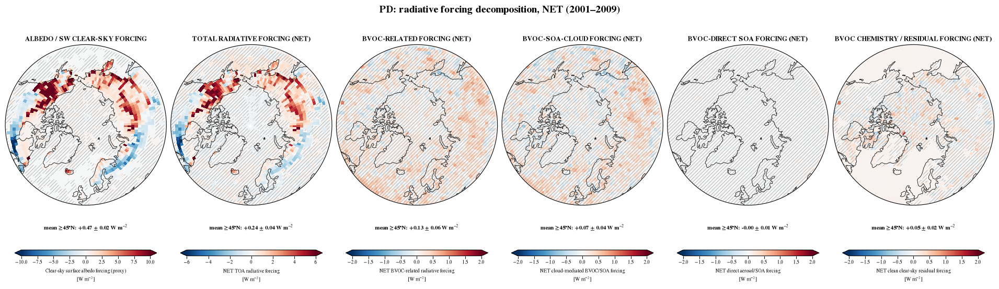

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_forcing_decomposition_SW_2001_2009.png


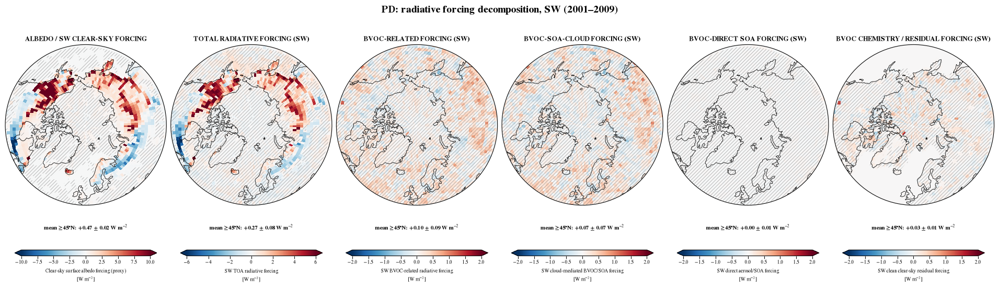

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_forcing_decomposition_LW_2001_2009.png


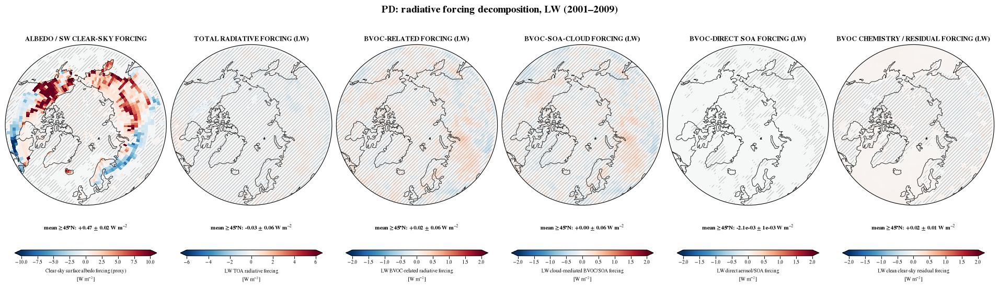

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_forcing_decomposition_NET_2001_2009.png


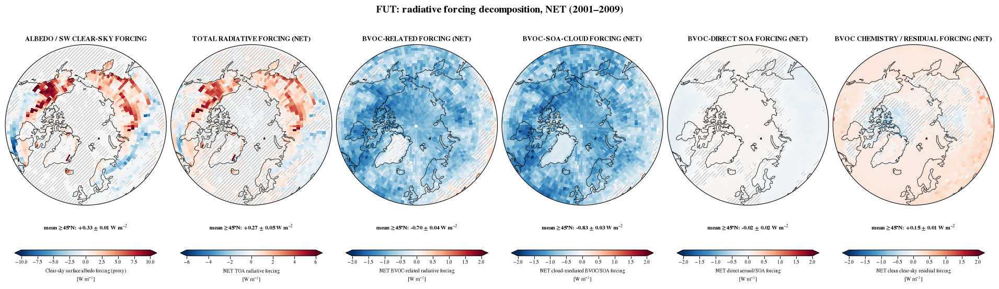

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_forcing_decomposition_SW_2001_2009.png


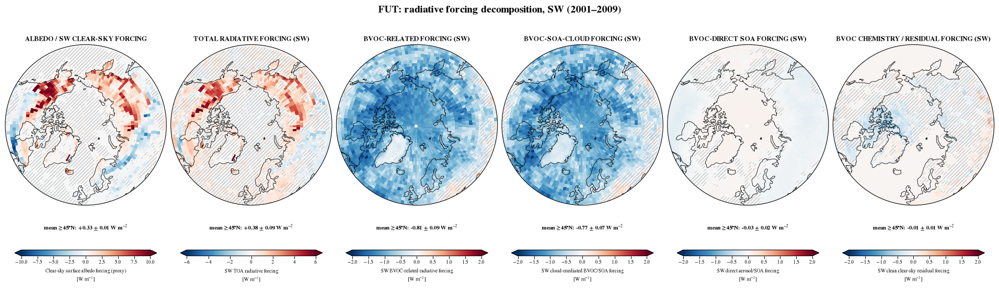

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_forcing_decomposition_LW_2001_2009.png


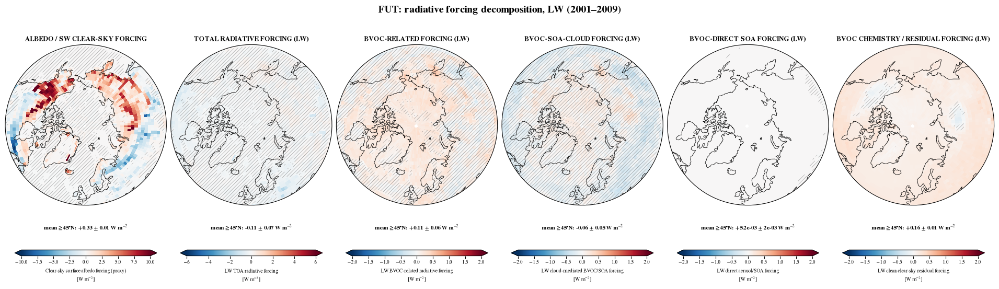

In [2]:
for exp in ("PD", "FUT"):
    for band in ("NET", "SW", "LW"):
        fig, axes = fm.make_forcing_summary_figure(exp, band=band, transparent_background=True, **common)
        plt.show(); plt.close(fig)

## 2. Ghan decomposition per contrast (total + 3 terms, shared colour scale)
One figure per period × contrast × band (18): LCC − CTRL, LCC − LCC_fBVOC and **LCC_fBVOC − CTRL** (land-cover change with emissions held at the CTRL_PD ISOP/MTERP climatology; LCC − CTRL = the other two summed). All four panels share one colour scale, so the terms can be compared by colour and visibly add up to the total.
The closure line checks max |d(ARI) + d(cloud) + d(clear-clean) − d(total)| over all cells and years (exact by construction; ~1e-5 W m⁻² = float32 rounding).

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-CTRL_NET_2001_2009.png


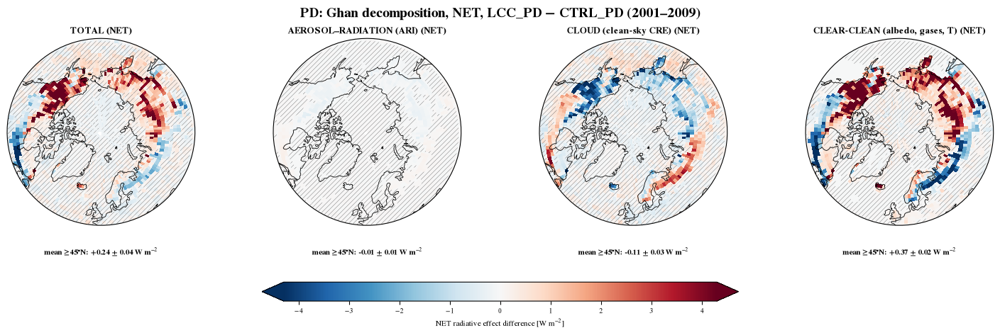

Ghan closure PD LCC-CTRL SW ANN: max |sum of terms - total| = 1.9e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-CTRL_SW_2001_2009.png


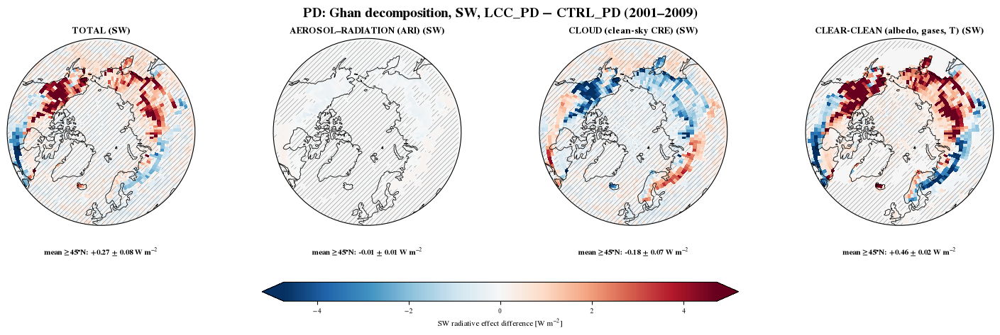

Ghan closure PD LCC-CTRL LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-CTRL_LW_2001_2009.png


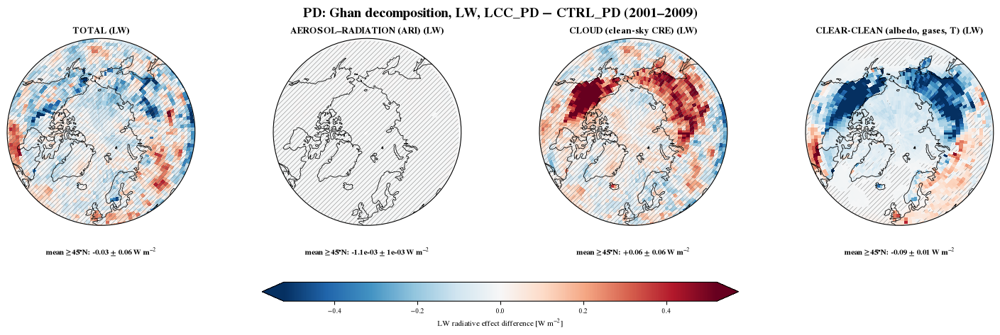

Ghan closure PD LCC-fBVOC NET ANN: max |sum of terms - total| = 6.9e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-fBVOC_NET_2001_2009.png


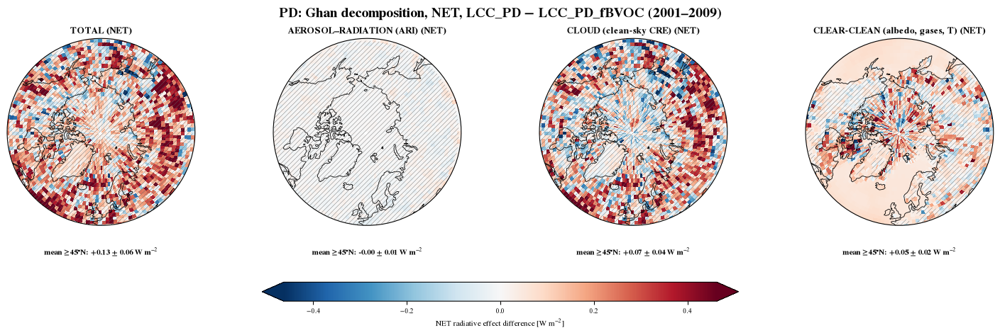

Ghan closure PD LCC-fBVOC SW ANN: max |sum of terms - total| = 1.9e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-fBVOC_SW_2001_2009.png


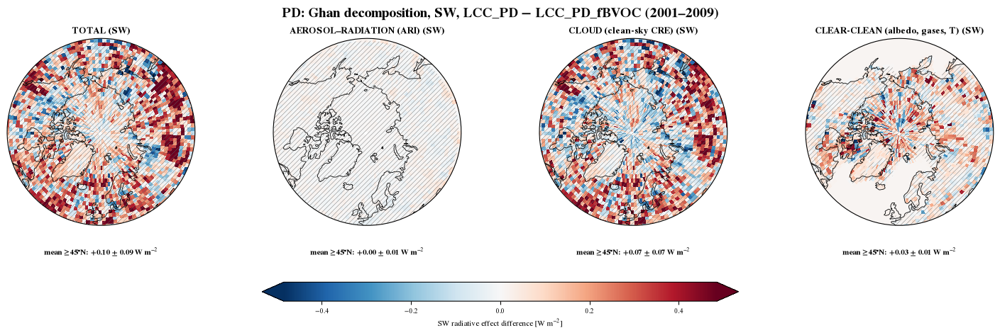

Ghan closure PD LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_LCC-fBVOC_LW_2001_2009.png


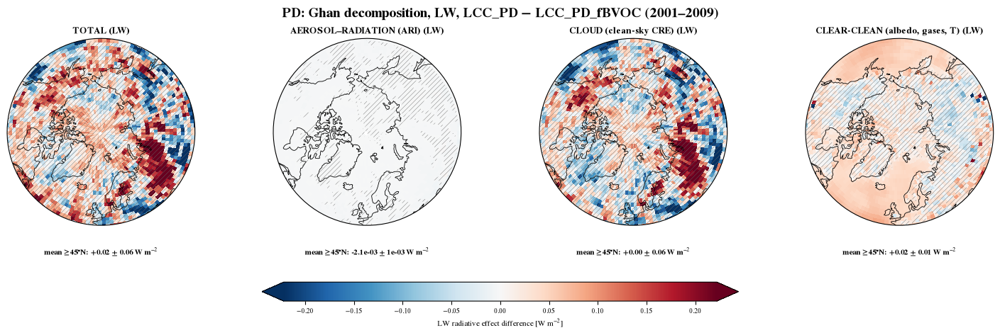

Ghan closure PD fBVOC-CTRL NET ANN: max |sum of terms - total| = 6.4e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_fBVOC-CTRL_NET_2001_2009.png


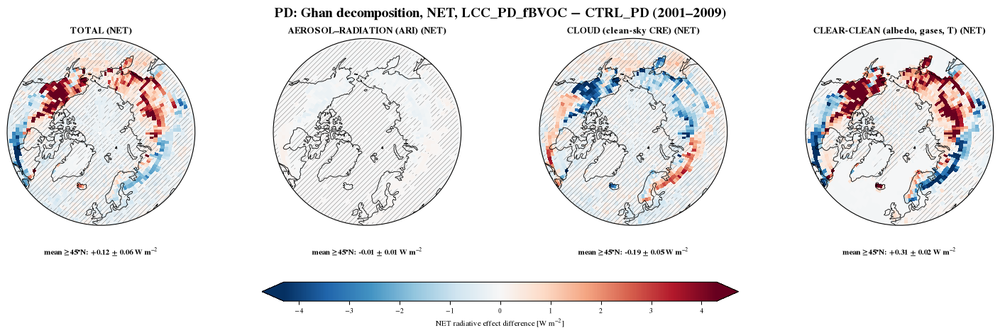

Ghan closure PD fBVOC-CTRL SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_fBVOC-CTRL_SW_2001_2009.png


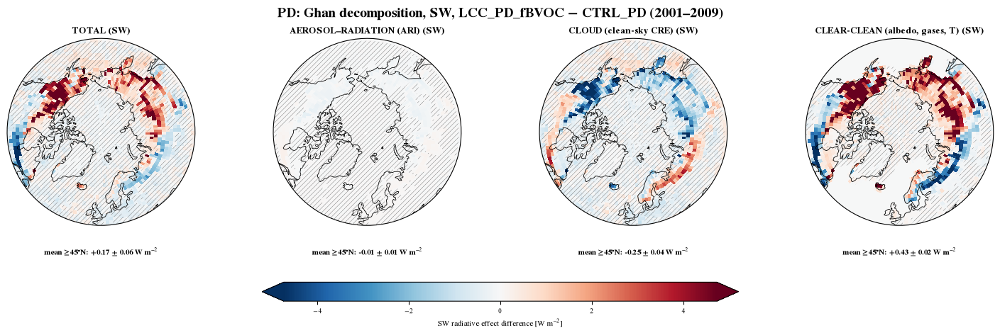

Ghan closure PD fBVOC-CTRL LW ANN: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_fBVOC-CTRL_LW_2001_2009.png


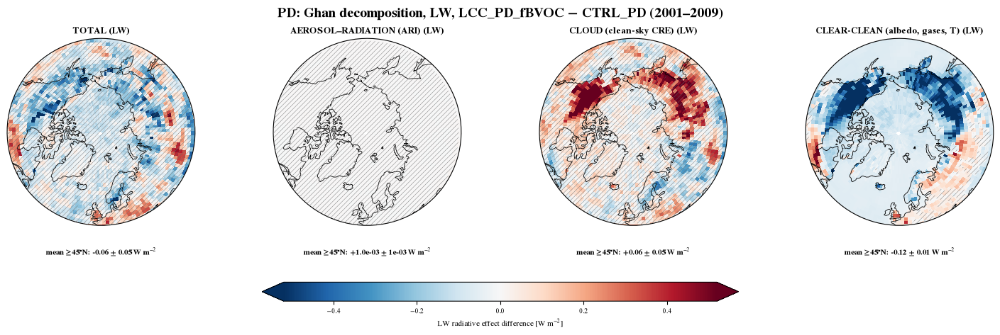

Ghan closure FUT LCC-CTRL NET ANN: max |sum of terms - total| = 6.7e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-CTRL_NET_2001_2009.png


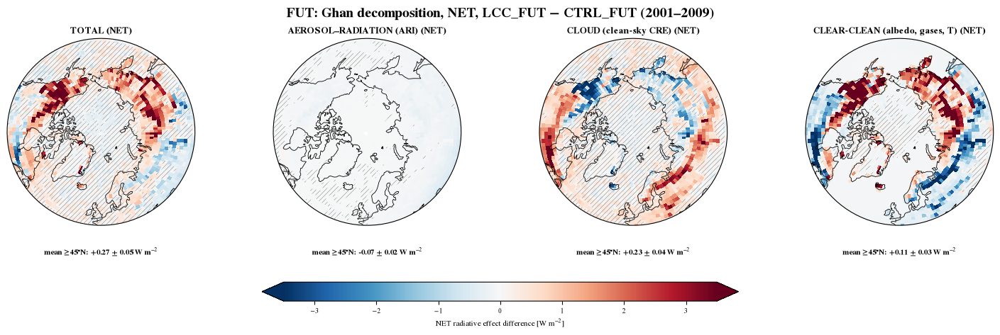

Ghan closure FUT LCC-CTRL SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-CTRL_SW_2001_2009.png


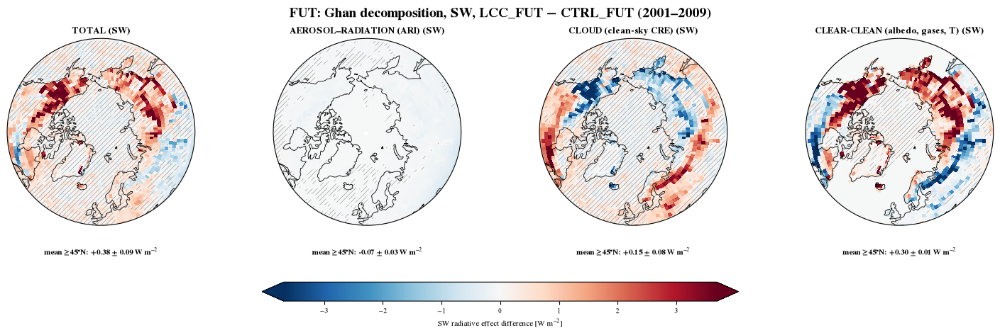

Ghan closure FUT LCC-CTRL LW ANN: max |sum of terms - total| = 6.3e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-CTRL_LW_2001_2009.png


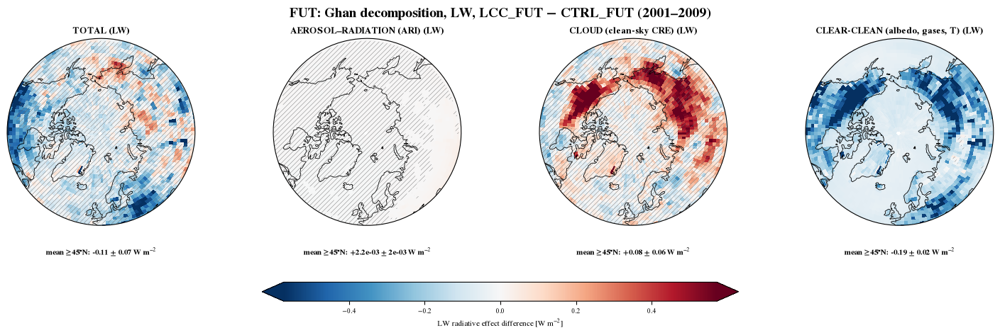

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 7.0e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOC_NET_2001_2009.png


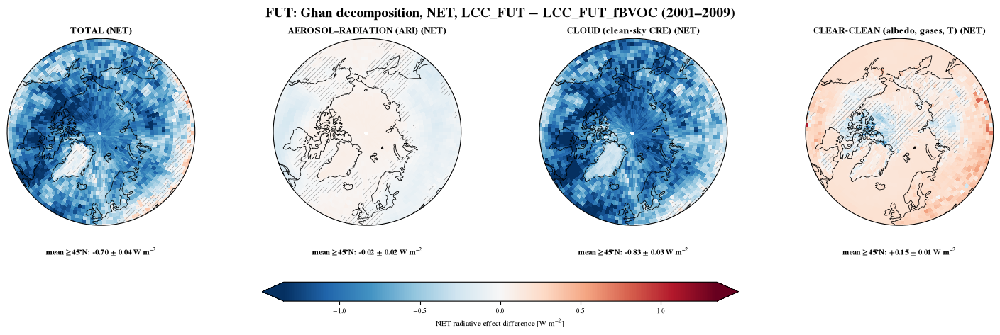

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOC_SW_2001_2009.png


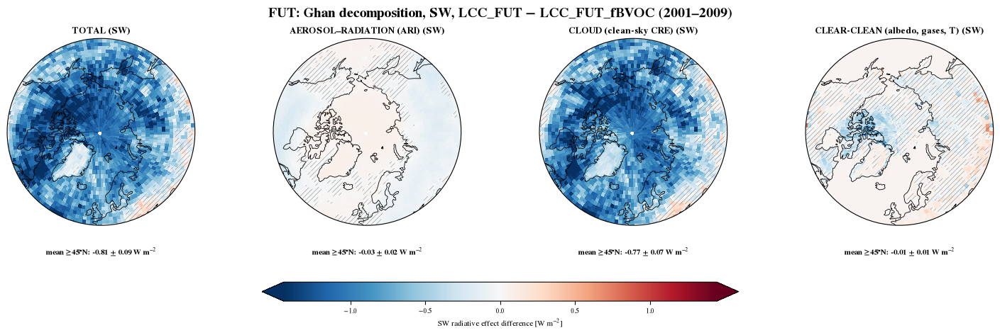

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOC_LW_2001_2009.png


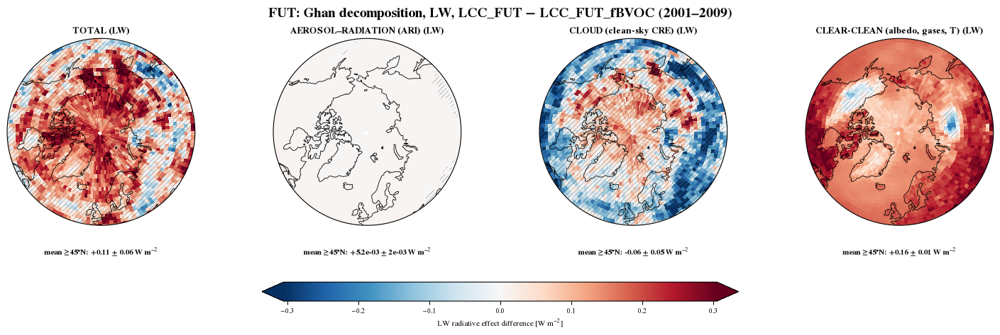

Ghan closure FUT fBVOC-CTRL NET ANN: max |sum of terms - total| = 6.5e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOC-CTRL_NET_2001_2009.png


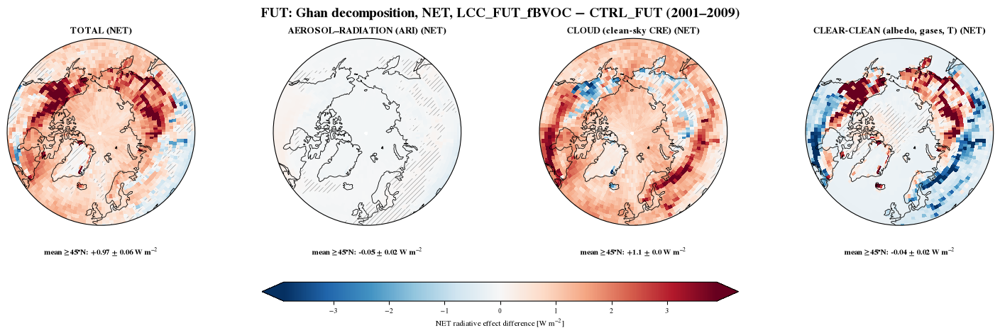

Ghan closure FUT fBVOC-CTRL SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOC-CTRL_SW_2001_2009.png


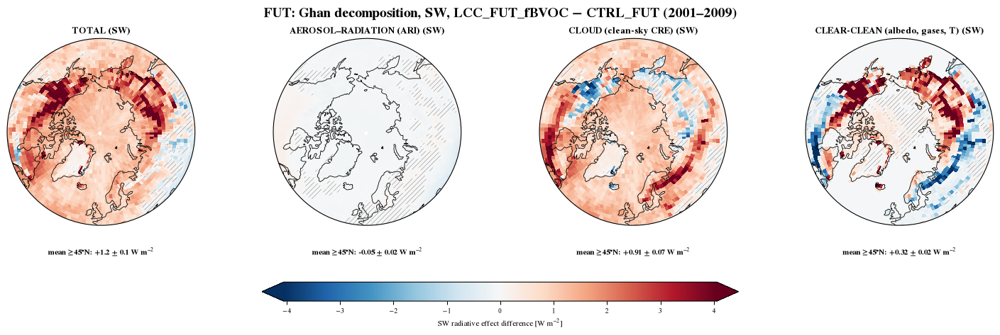

Ghan closure FUT fBVOC-CTRL LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOC-CTRL_LW_2001_2009.png


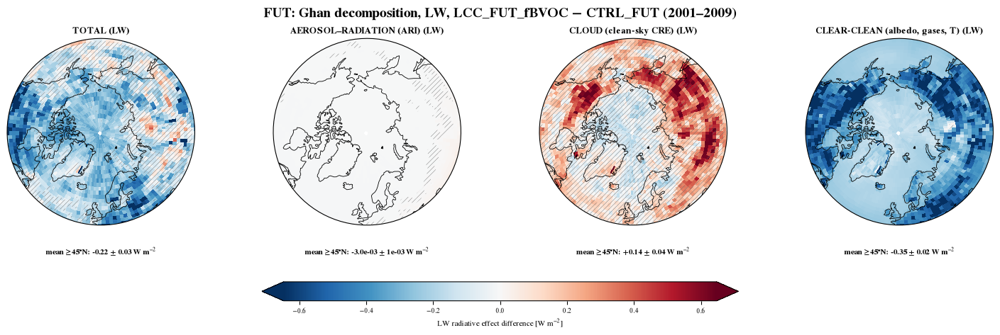

In [3]:
for exp in ("PD", "FUT"):
    for contrast in fm.GHAN_CONTRASTS:   # LCC-CTRL, LCC-fBVOC, fBVOC-CTRL
        for band in ("NET", "SW", "LW"):
            fig, axes = fm.make_ghan_figure(exp, contrast, band, start_year=START_YEAR, end_year=END_YEAR)
            plt.show(); plt.close(fig)

## 3. Seasonal Ghan decomposition (DJF / MAM / JJA / SON)
Same four terms, one row per season, one colour scale per row. Separates the snow-masking albedo signal (spring, clear-clean SW) from the cloud and aerosol terms (summer).
Seasonal means are month-length weighted within each calendar year; **DJF = Jan + Feb + Dec of the same year**, so all 9 years stay paired.

Ghan closure PD LCC-CTRL NET DJF: max |sum of terms - total| = 2.1e-05 W m-2
Ghan closure PD LCC-CTRL NET MAM: max |sum of terms - total| = 1.8e-05 W m-2
Ghan closure PD LCC-CTRL NET JJA: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure PD LCC-CTRL NET SON: max |sum of terms - total| = 1.8e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-CTRL_NET_2001_2009.png


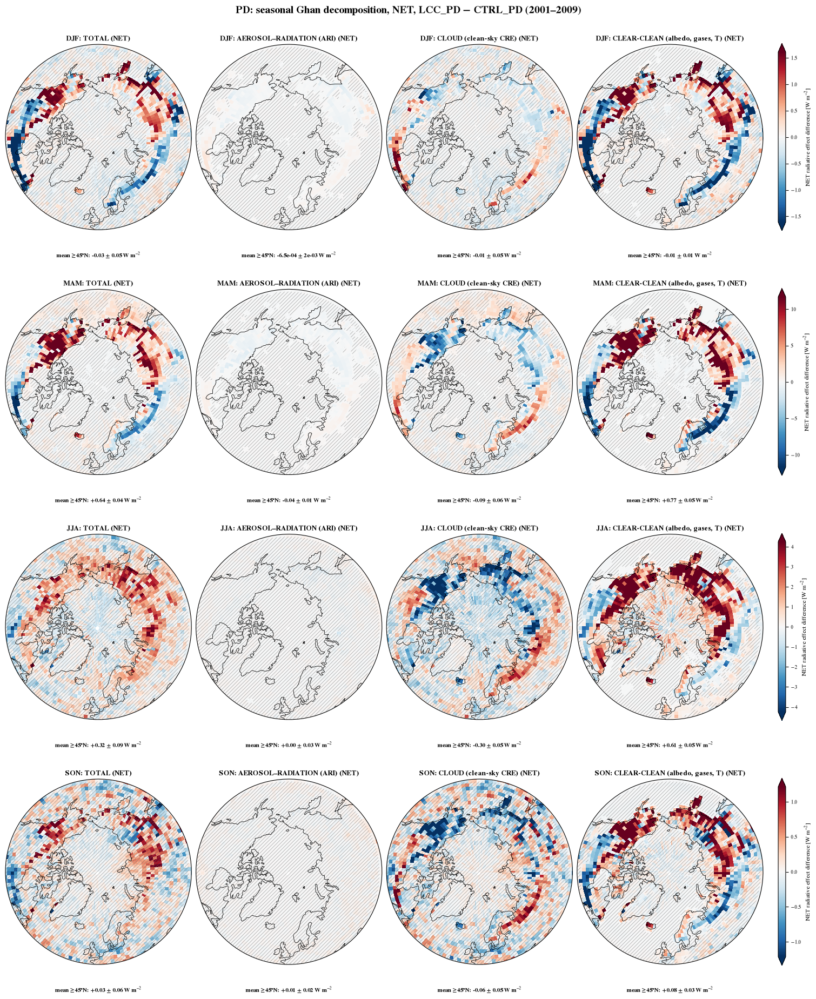

Ghan closure PD LCC-CTRL SW DJF: max |sum of terms - total| = 7.9e-06 W m-2
Ghan closure PD LCC-CTRL SW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD LCC-CTRL SW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD LCC-CTRL SW SON: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-CTRL_SW_2001_2009.png


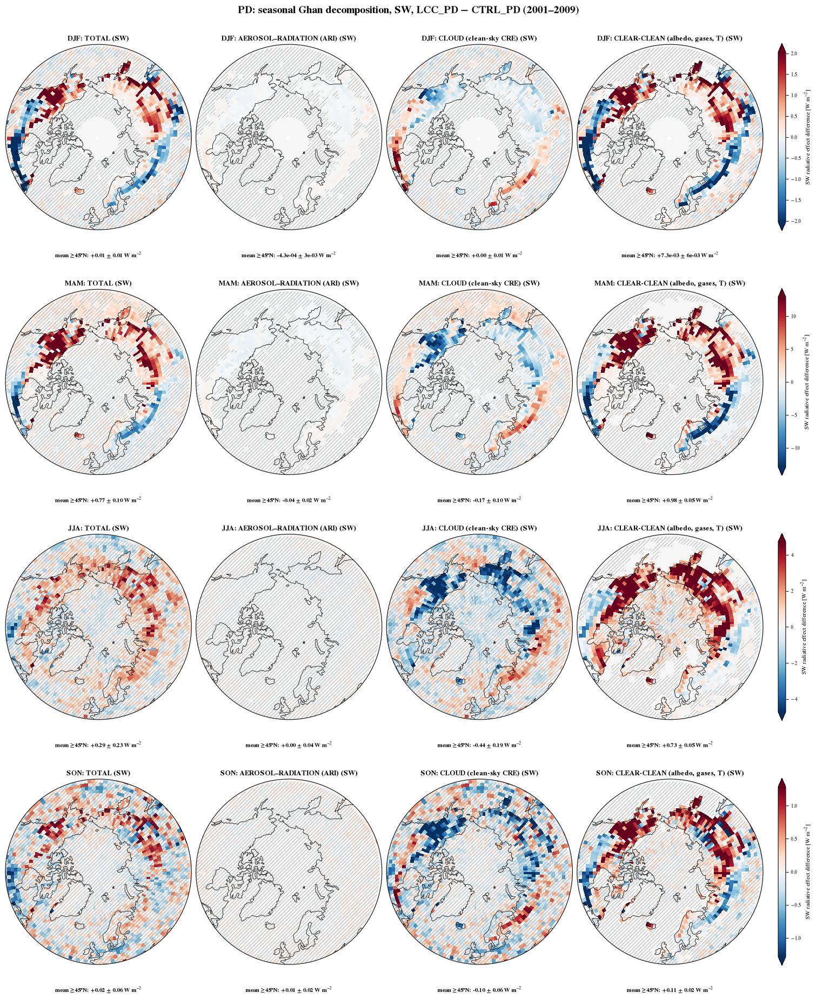

Ghan closure PD LCC-CTRL LW DJF: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure PD LCC-CTRL LW MAM: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure PD LCC-CTRL LW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD LCC-CTRL LW SON: max |sum of terms - total| = 2.6e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-CTRL_LW_2001_2009.png


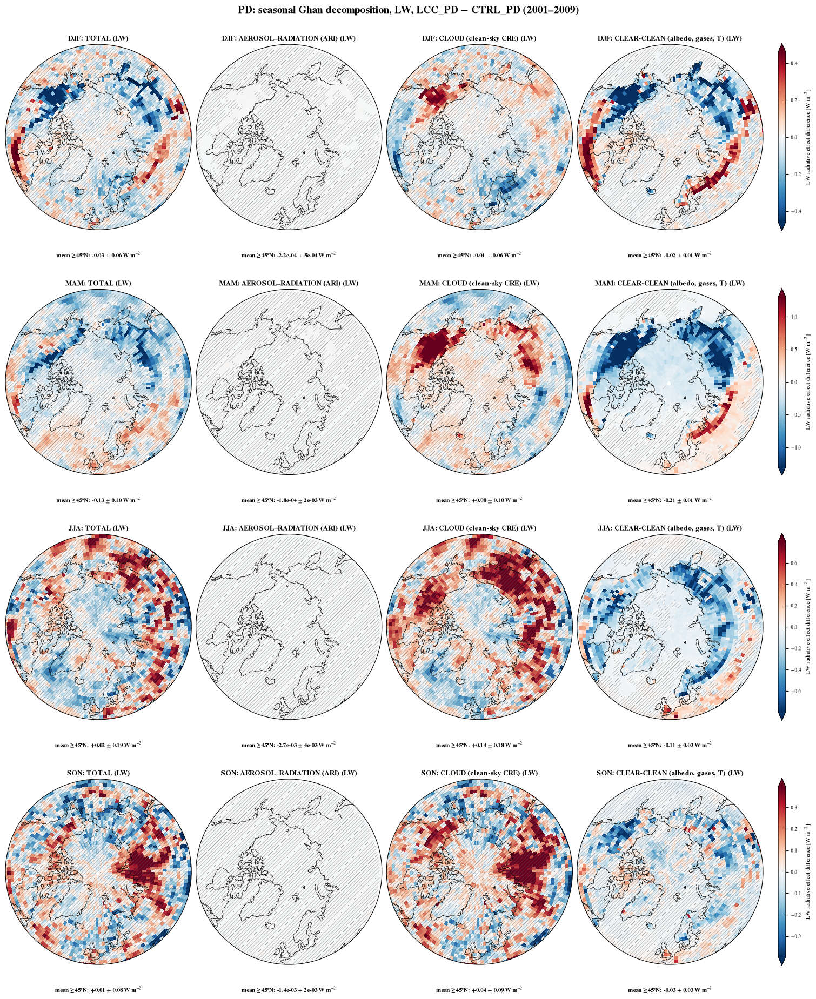

Ghan closure PD LCC-fBVOC NET DJF: max |sum of terms - total| = 1.9e-05 W m-2
Ghan closure PD LCC-fBVOC NET MAM: max |sum of terms - total| = 1.7e-05 W m-2
Ghan closure PD LCC-fBVOC NET JJA: max |sum of terms - total| = 2.1e-05 W m-2
Ghan closure PD LCC-fBVOC NET SON: max |sum of terms - total| = 1.7e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-fBVOC_NET_2001_2009.png


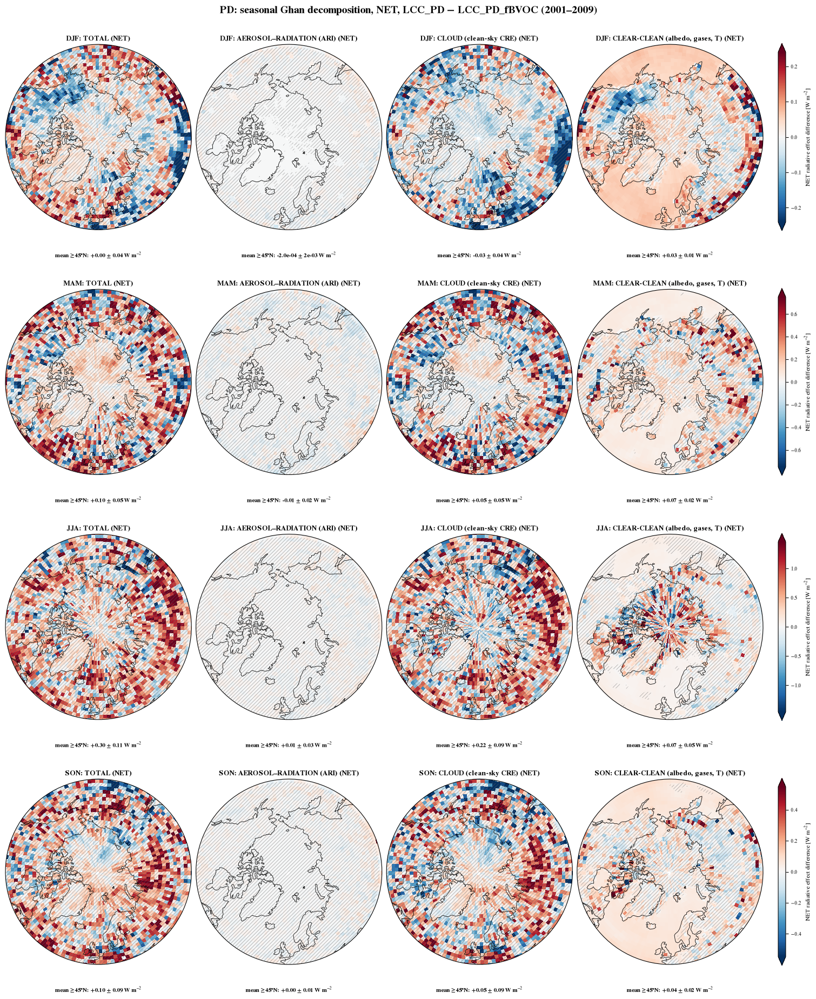

Ghan closure PD LCC-fBVOC SW DJF: max |sum of terms - total| = 7.9e-06 W m-2
Ghan closure PD LCC-fBVOC SW MAM: max |sum of terms - total| = 1.2e-13 W m-2
Ghan closure PD LCC-fBVOC SW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD LCC-fBVOC SW SON: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-fBVOC_SW_2001_2009.png


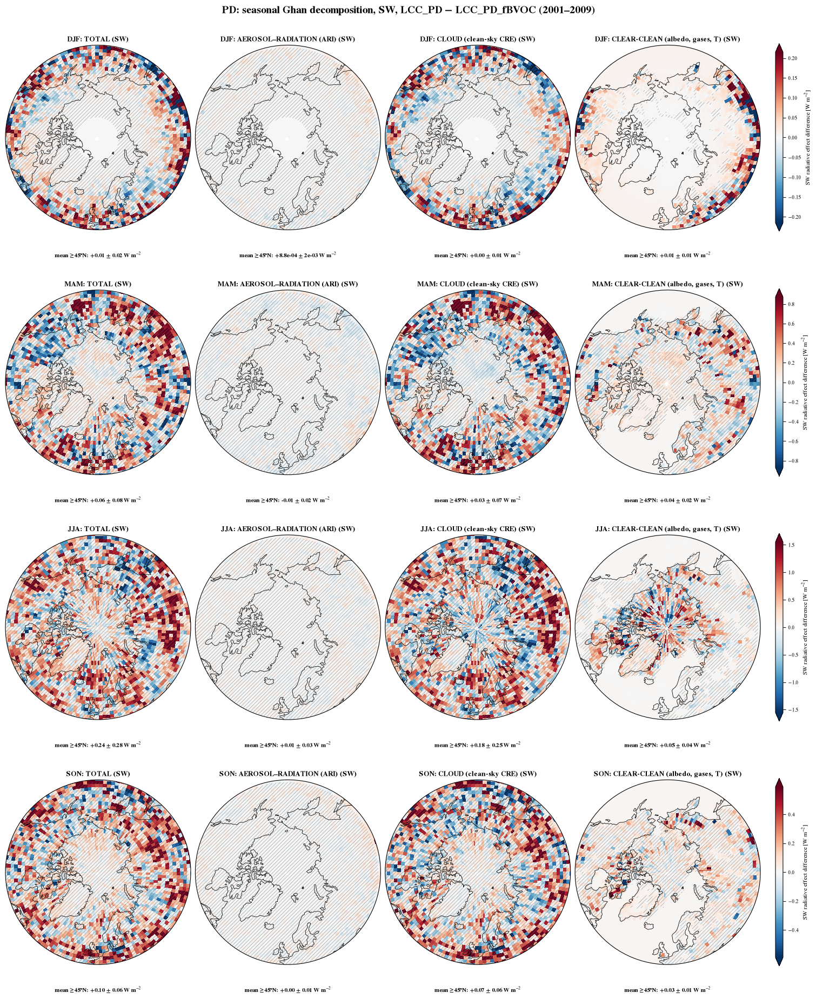

Ghan closure PD LCC-fBVOC LW DJF: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure PD LCC-fBVOC LW MAM: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure PD LCC-fBVOC LW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD LCC-fBVOC LW SON: max |sum of terms - total| = 2.6e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_LCC-fBVOC_LW_2001_2009.png


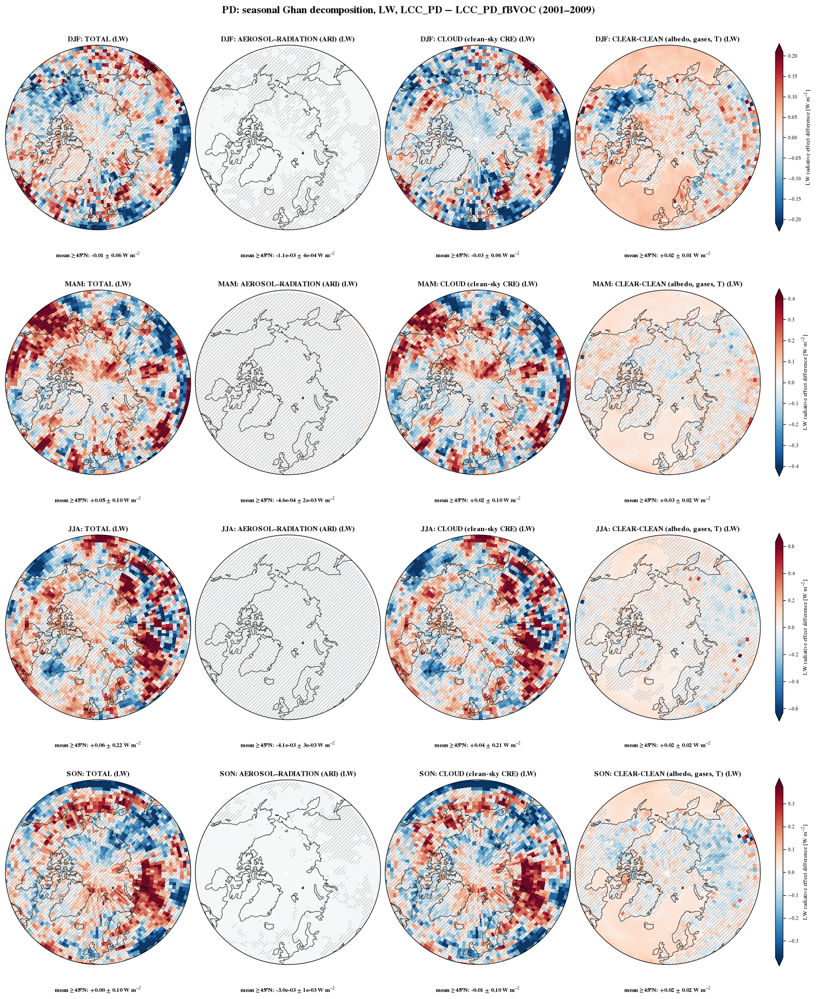

Ghan closure PD fBVOC-CTRL NET DJF: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure PD fBVOC-CTRL NET MAM: max |sum of terms - total| = 1.7e-05 W m-2
Ghan closure PD fBVOC-CTRL NET JJA: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure PD fBVOC-CTRL NET SON: max |sum of terms - total| = 1.8e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_fBVOC-CTRL_NET_2001_2009.png


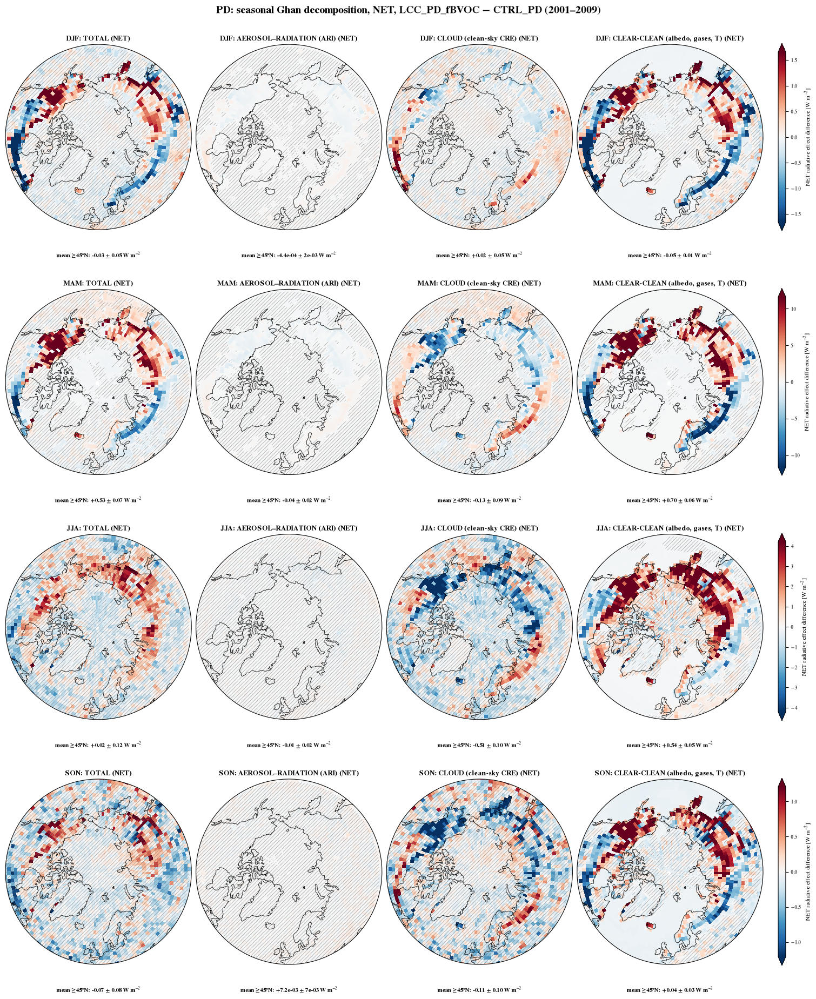

Ghan closure PD fBVOC-CTRL SW DJF: max |sum of terms - total| = 5.3e-06 W m-2
Ghan closure PD fBVOC-CTRL SW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD fBVOC-CTRL SW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD fBVOC-CTRL SW SON: max |sum of terms - total| = 1.2e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_fBVOC-CTRL_SW_2001_2009.png


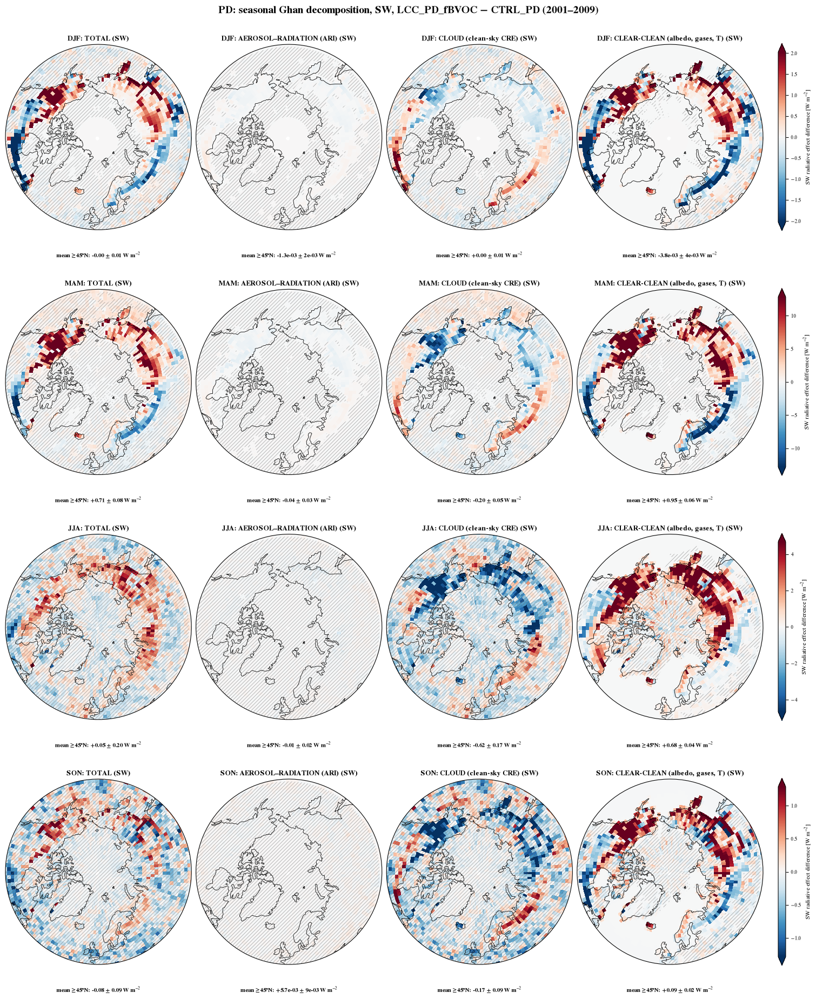

Ghan closure PD fBVOC-CTRL LW DJF: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure PD fBVOC-CTRL LW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD fBVOC-CTRL LW JJA: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure PD fBVOC-CTRL LW SON: max |sum of terms - total| = 1.0e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_ghan_seasonal_fBVOC-CTRL_LW_2001_2009.png


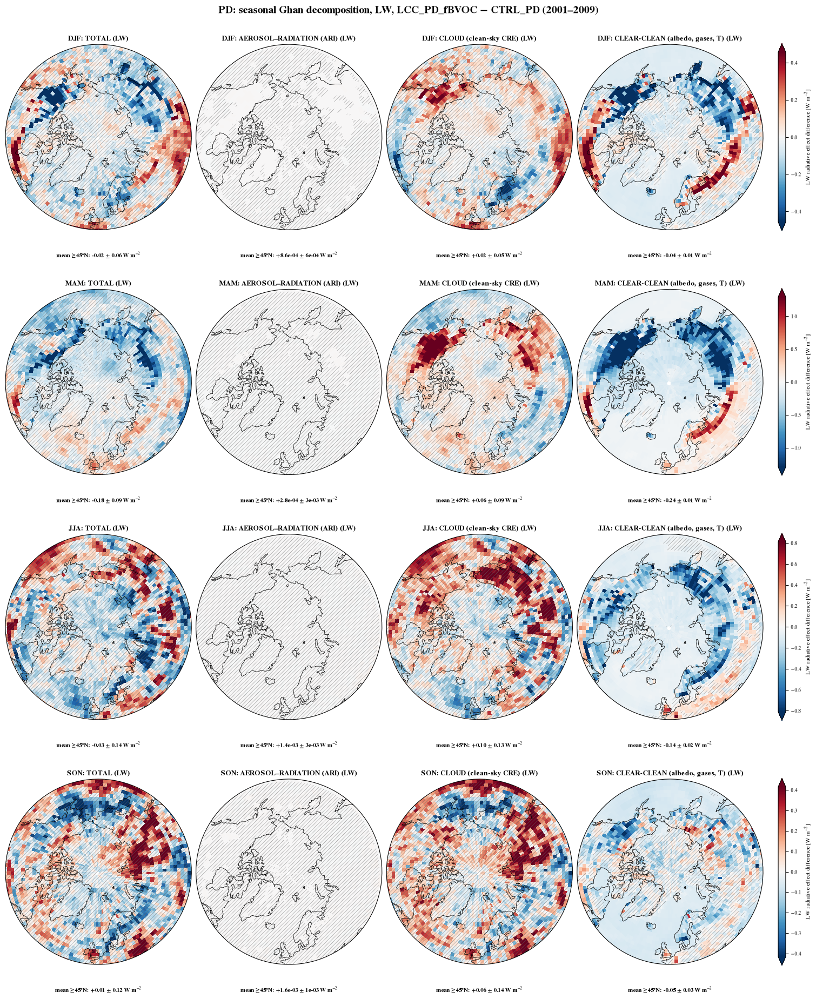

Ghan closure FUT LCC-CTRL NET DJF: max |sum of terms - total| = 1.9e-05 W m-2
Ghan closure FUT LCC-CTRL NET MAM: max |sum of terms - total| = 1.5e-05 W m-2
Ghan closure FUT LCC-CTRL NET JJA: max |sum of terms - total| = 2.2e-05 W m-2
Ghan closure FUT LCC-CTRL NET SON: max |sum of terms - total| = 1.7e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-CTRL_NET_2001_2009.png


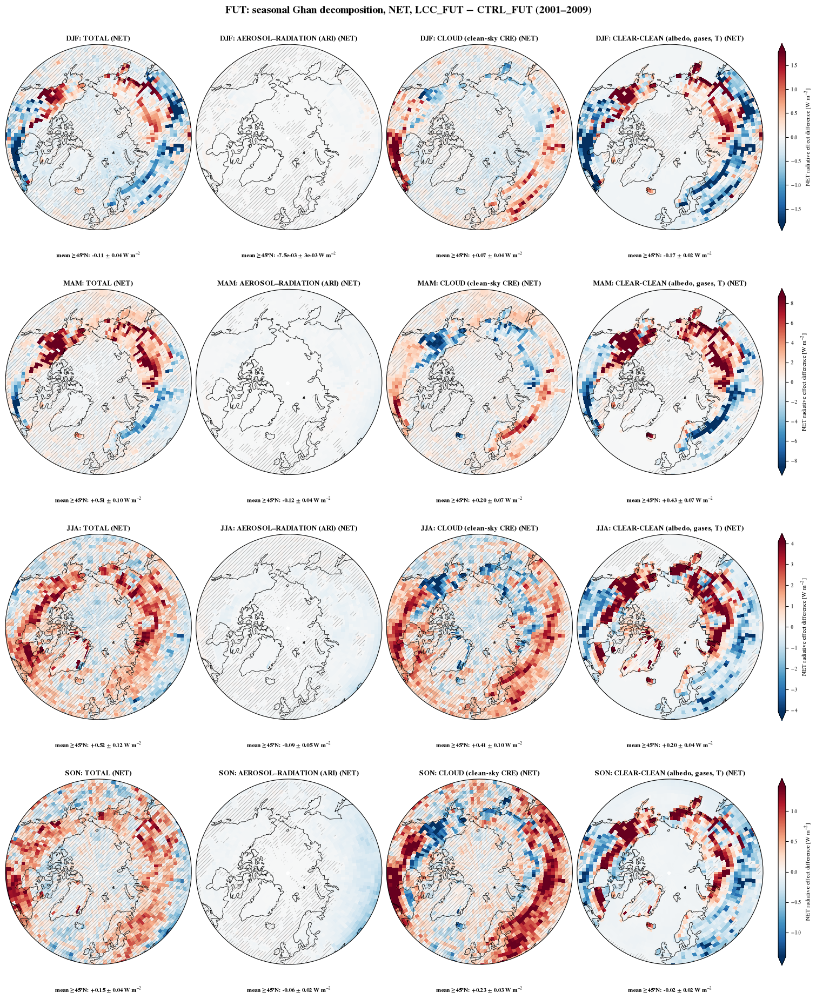

Ghan closure FUT LCC-CTRL SW DJF: max |sum of terms - total| = 2.6e-06 W m-2
Ghan closure FUT LCC-CTRL SW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT LCC-CTRL SW JJA: max |sum of terms - total| = 5.1e-06 W m-2
Ghan closure FUT LCC-CTRL SW SON: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-CTRL_SW_2001_2009.png


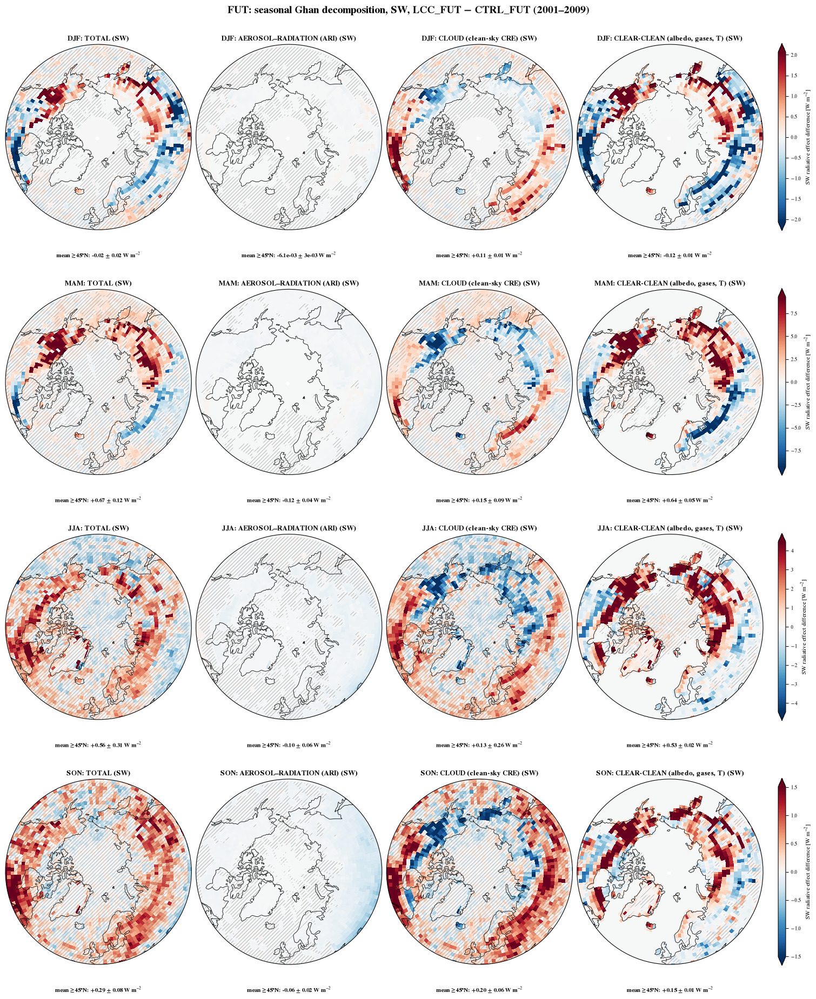

Ghan closure FUT LCC-CTRL LW DJF: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT LCC-CTRL LW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT LCC-CTRL LW JJA: max |sum of terms - total| = 2.5e-06 W m-2
Ghan closure FUT LCC-CTRL LW SON: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-CTRL_LW_2001_2009.png


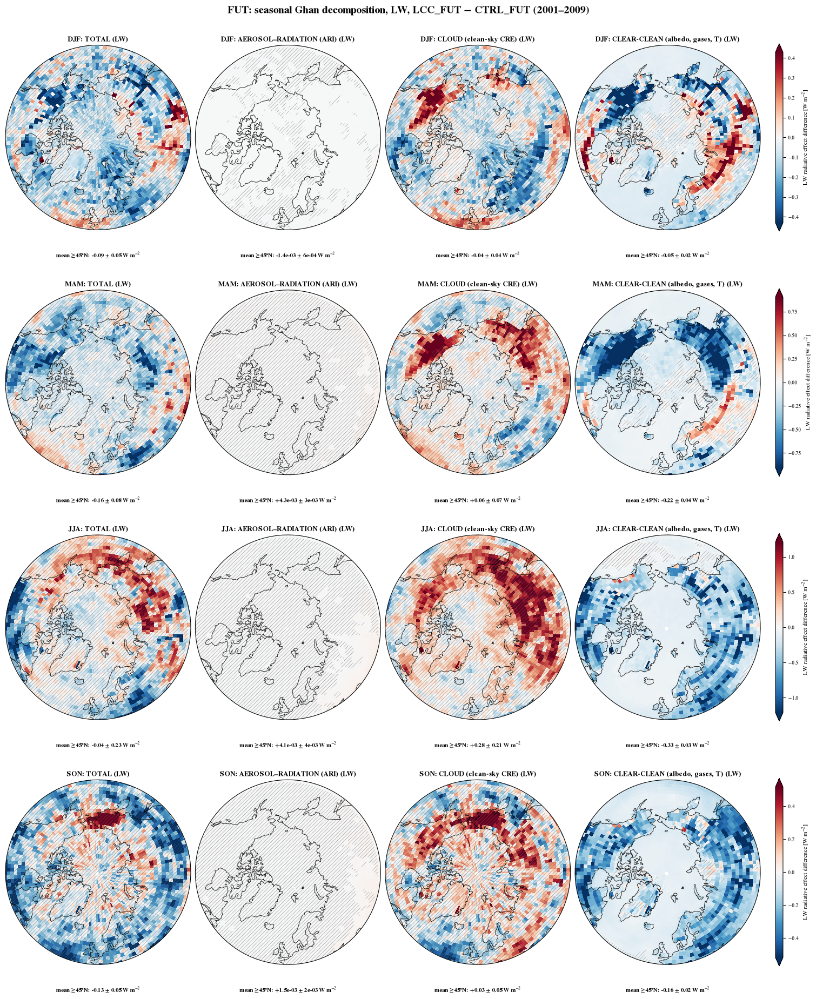

Ghan closure FUT LCC-fBVOC NET DJF: max |sum of terms - total| = 1.9e-05 W m-2
Ghan closure FUT LCC-fBVOC NET MAM: max |sum of terms - total| = 1.7e-05 W m-2
Ghan closure FUT LCC-fBVOC NET JJA: max |sum of terms - total| = 2.1e-05 W m-2
Ghan closure FUT LCC-fBVOC NET SON: max |sum of terms - total| = 1.7e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-fBVOC_NET_2001_2009.png


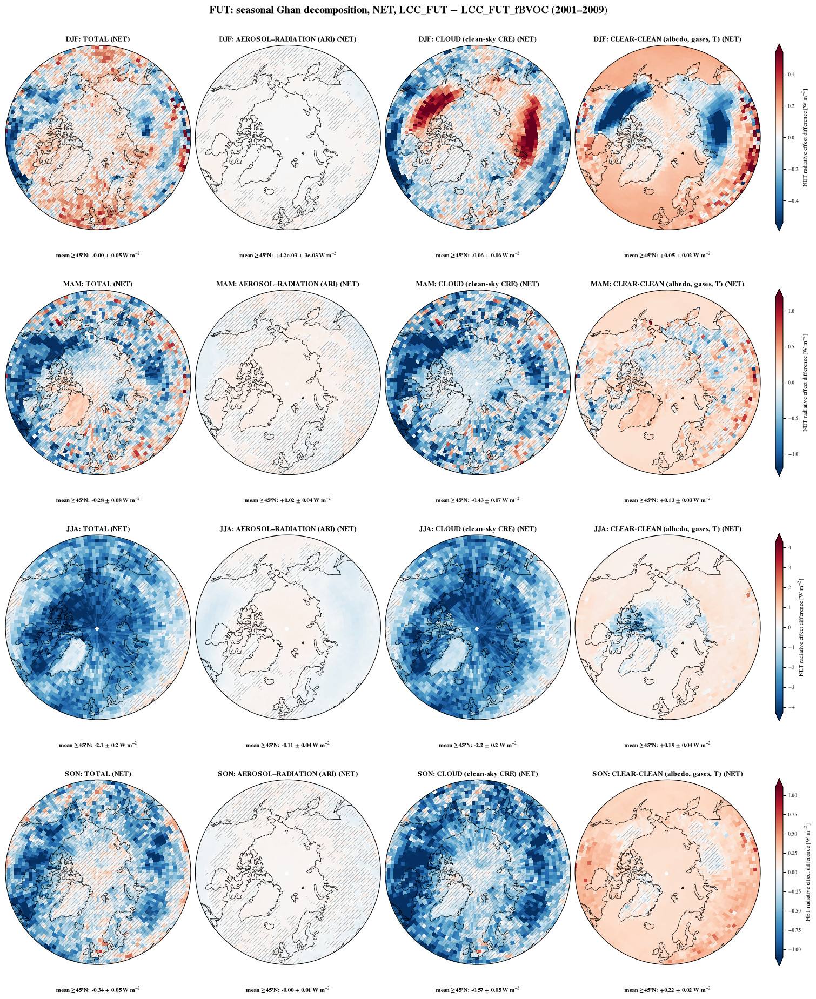

Ghan closure FUT LCC-fBVOC SW DJF: max |sum of terms - total| = 5.3e-06 W m-2
Ghan closure FUT LCC-fBVOC SW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT LCC-fBVOC SW JJA: max |sum of terms - total| = 2.6e-06 W m-2
Ghan closure FUT LCC-fBVOC SW SON: max |sum of terms - total| = 1.1e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-fBVOC_SW_2001_2009.png


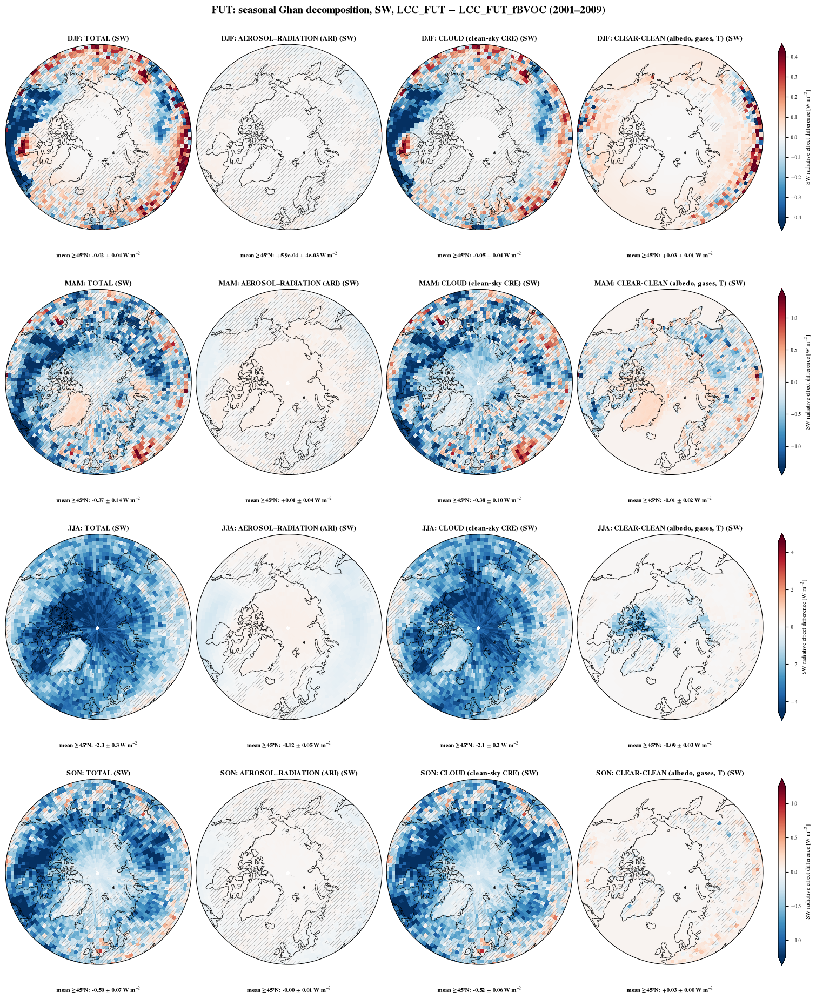

Ghan closure FUT LCC-fBVOC LW DJF: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure FUT LCC-fBVOC LW MAM: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure FUT LCC-fBVOC LW JJA: max |sum of terms - total| = 2.5e-06 W m-2
Ghan closure FUT LCC-fBVOC LW SON: max |sum of terms - total| = 2.6e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_LCC-fBVOC_LW_2001_2009.png


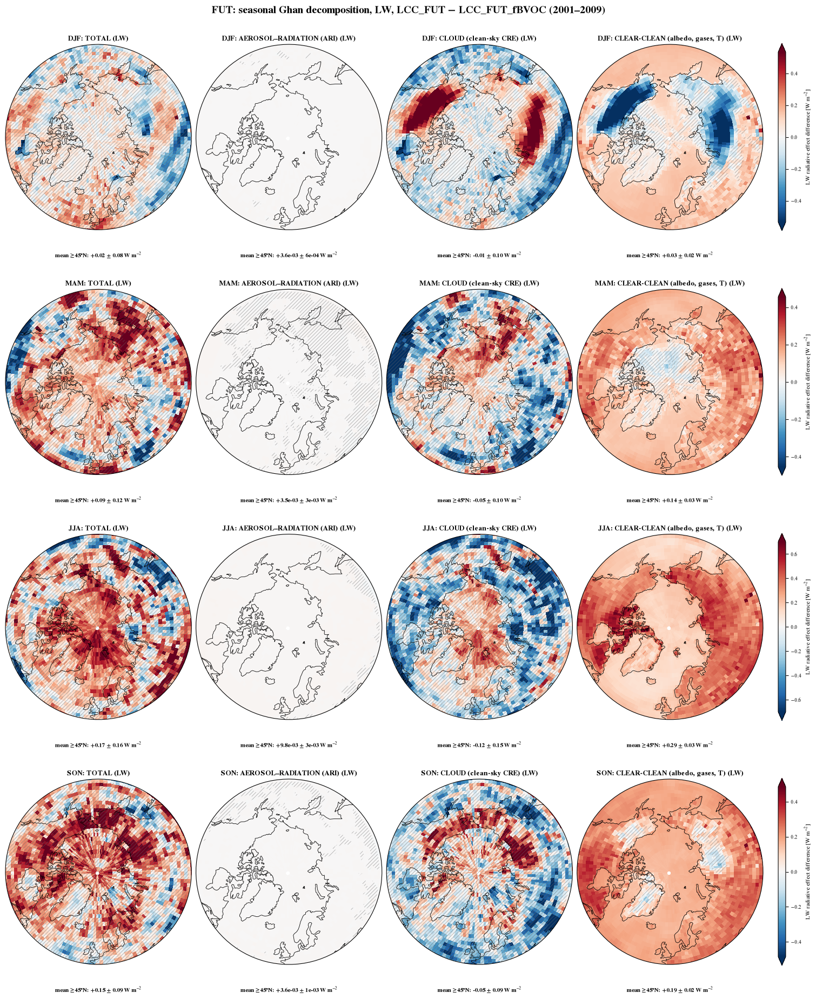

Ghan closure FUT fBVOC-CTRL NET DJF: max |sum of terms - total| = 1.8e-05 W m-2
Ghan closure FUT fBVOC-CTRL NET MAM: max |sum of terms - total| = 1.7e-05 W m-2
Ghan closure FUT fBVOC-CTRL NET JJA: max |sum of terms - total| = 2.1e-05 W m-2
Ghan closure FUT fBVOC-CTRL NET SON: max |sum of terms - total| = 1.7e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_fBVOC-CTRL_NET_2001_2009.png


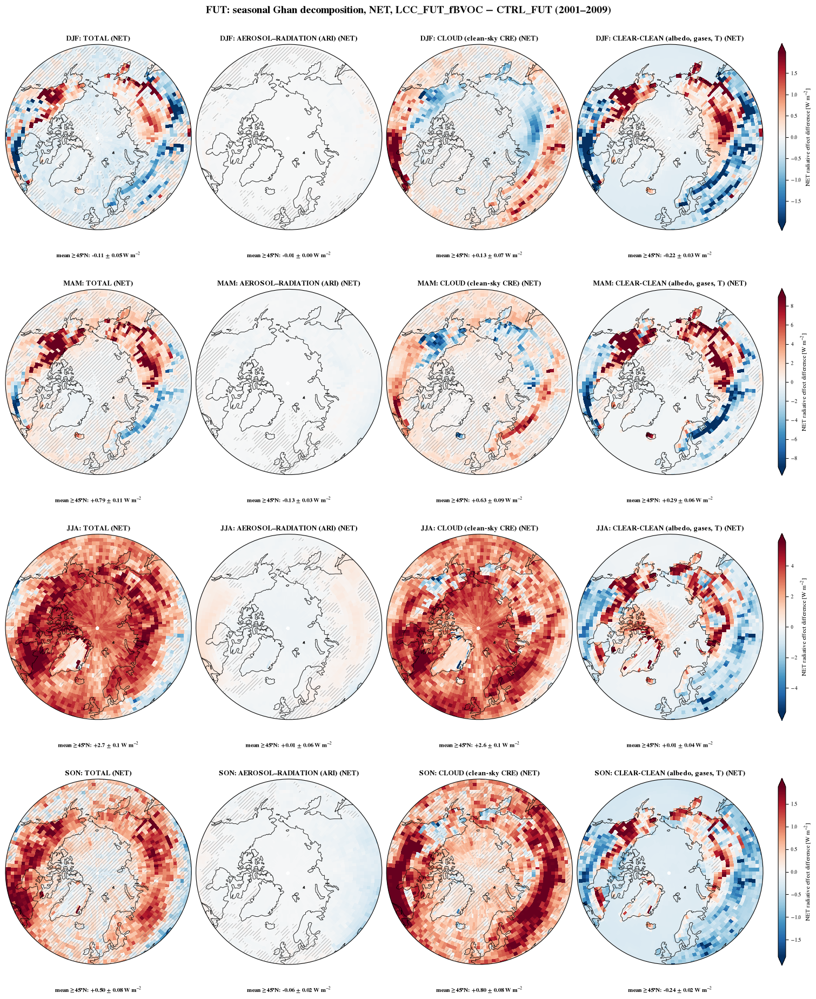

Ghan closure FUT fBVOC-CTRL SW DJF: max |sum of terms - total| = 2.6e-06 W m-2
Ghan closure FUT fBVOC-CTRL SW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT fBVOC-CTRL SW JJA: max |sum of terms - total| = 5.1e-06 W m-2
Ghan closure FUT fBVOC-CTRL SW SON: max |sum of terms - total| = 1.2e-13 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_fBVOC-CTRL_SW_2001_2009.png


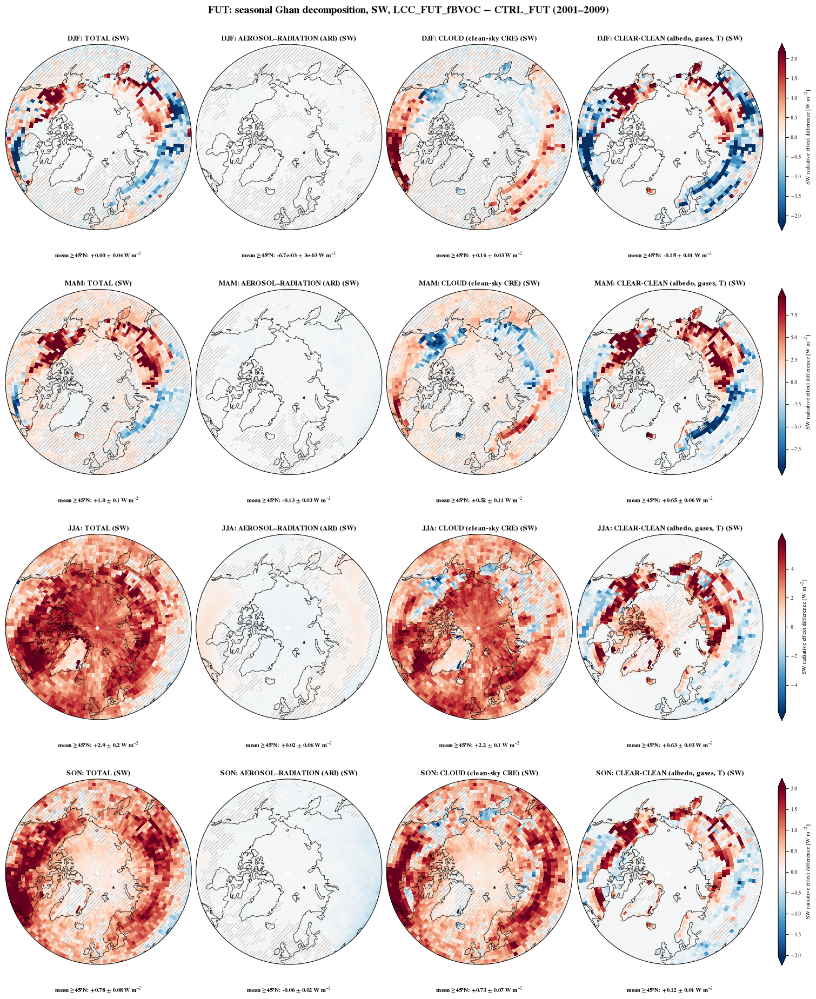

Ghan closure FUT fBVOC-CTRL LW DJF: max |sum of terms - total| = 1.0e-13 W m-2
Ghan closure FUT fBVOC-CTRL LW MAM: max |sum of terms - total| = 1.1e-13 W m-2
Ghan closure FUT fBVOC-CTRL LW JJA: max |sum of terms - total| = 2.5e-06 W m-2
Ghan closure FUT fBVOC-CTRL LW SON: max |sum of terms - total| = 2.6e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_seasonal_fBVOC-CTRL_LW_2001_2009.png


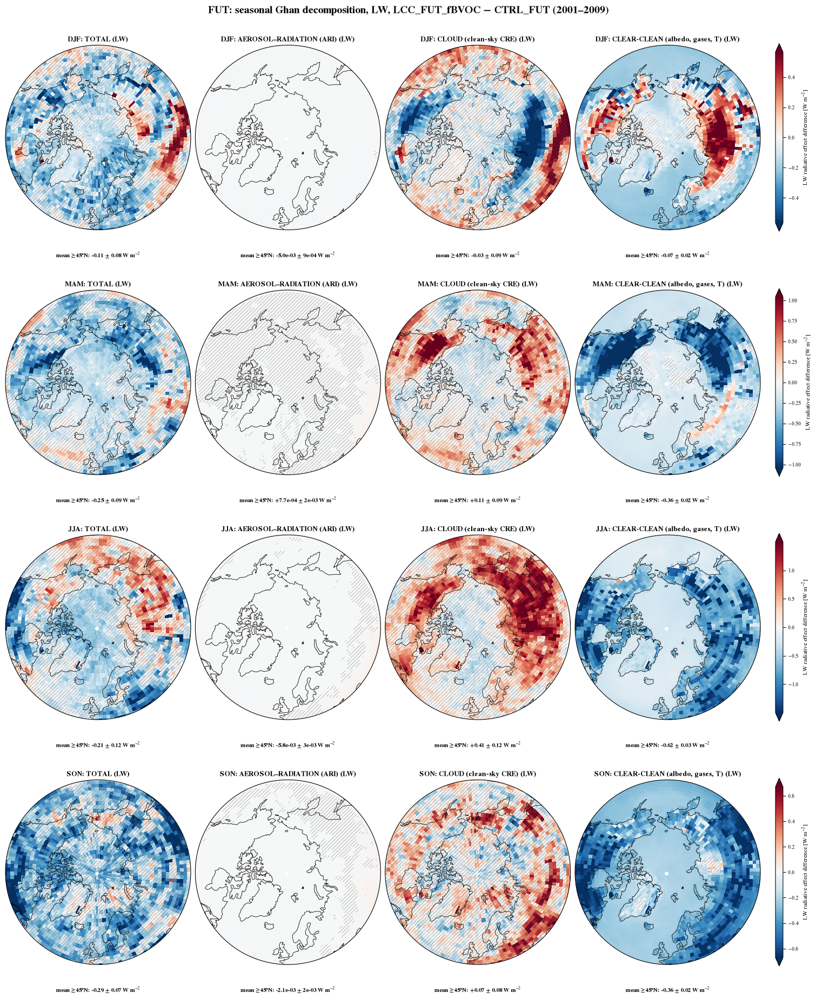

In [4]:
for exp in ("PD", "FUT"):
    for contrast in fm.GHAN_CONTRASTS:   # LCC-CTRL, LCC-fBVOC, fBVOC-CTRL
        for band in ("NET", "SW", "LW"):
            fig, axes = fm.make_ghan_figure(exp, contrast, band, seasonal=True,
                                            start_year=START_YEAR, end_year=END_YEAR)
            plt.show(); plt.close(fig)

## 4. Single map (quick look)

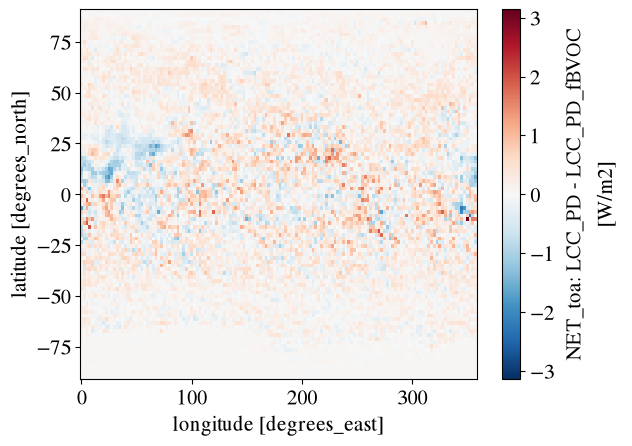

In [5]:
da = fm.difference_map("LCC_PD", fm.BVOC_PAIRS["PD"]["fbvoc"], "RADIATIVE", "NET_toa", START_YEAR, END_YEAR)
da.plot()